# 1. Meshgrid test — Python

This notebook uses the five-cavity L-band example from the KlyC User Manual. 

Regarding the definition and build of the longitudinal mesh translated from `KLJCmainsv22.m`:
1. It evaluates the translated `KLJCmainsv22.m` section (lines 49-96 and 132-133) in Python.
2. Exports all MATLAB inputs, and saves a checkpoint for numerical comparison.

### Warning:
Edit the input cell and **Restart Kernel and Run All**. This is a **one-dimensional longitudinal grid**: the radial drawings are geometry schematics, not a transverse mesh.
The companion MATLAB test is in `meshgrid_test.mlx` (or `meshgrid_test.m`). Passing the checks below does **not** demonstrate agreement with MATLAB. See [the test README](../README.md) for the workflow.

In [13]:
# Import necessary libraries and modules

from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import savemat
from IPython.display import Markdown, display

In [14]:
# Import custom modules and classes to be tested

current_directory = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current_directory, *current_directory.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "grid.py").exists()
)
test_directory = project_directory / "test" / "1.meshgrid_test"
sys.path.insert(0, str(project_directory / "src"))

from constants import c, etom, mu01
from model.beam import BeamParameters
from model.cavity import CavityParameters
from model.settings import NumericalSettings
from model.tube import TubeParameters
from solver.reference import ReferenceParameters
from solver.grid import GridParameters

In [15]:
# Set global options for numpy and matplotlib

np.set_printoptions(precision=6, linewidth=140)
# Apply the same dashed gray grid to every subplot.
# "line" places the grid above shaded regions, but below plotted lines.
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "axes.axisbelow": "line",
    "grid.color": "gray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
})

# Display options for Jupyter Notebook Tables

def show_table(rows):
    text = "| Variable | Value | Units | Meaning |\n"
    text += "|---|---|---|---|\n"
    for name, value, units, meaning in rows:
        if isinstance(value, np.ndarray):
            value = np.array2string(value, precision=5, max_line_width=1000)
        elif isinstance(value, (float, np.floating)):
            value = f"{value:.8g}"
        text += f"| `{name}` | {value} | {units} | {meaning} |\n"
    display(Markdown(text))

## 1. Editable inputs

All lengths below are in **mm**, frequencies in **GHz**, beam voltages in **kV**, and currents in **A**. Negative current represents electrons.

- `Nz` sets the requested spatial resolution per electromagnetic wavelength.
- `Nt` sets the number of emission-phase samples per RF period. It does not set the spatial resolution.
- `rcv[0]` contains physical longitudinal positions; `rcv[1]` contains radius multipliers, so the physical tunnel radius is `rc * rcv[1]`.
- The other circuit and iteration parameters are supplied because the existing parameter classes require them. They do not trigger a circuit solution here.

In [16]:
# Beam and emission samples
Nbeam = 1
rm1 = 0.0
rm2 = 6.0
rc = 10.0
Nt = 128
t0 = 2.0 * np.pi * np.arange(Nt) / Nt
tn1 = t0.copy()
Y0 = np.arange(Nt)
Ut = np.full(Nt, 180.0)
Izt = np.full(Nt, -16.0)

# Cavity centers and RF parameters (no RF fields are calculated)
Nc = 5
f = 1.0
f0 = np.array([1.000, 1.006, 1.016, 1.030, 1.000])
zshift = np.array([0.0, 480.0, 1630.0, 2400.0, 2730.0])
type = np.array([0, 1, 1, 1, -1])
nh = np.ones(Nc, dtype=int)
Qext = np.array([334.0, 95000.0, 95000.0, 95000.0, 50.0])
Qin = np.array([16428.0, 19768.0, 19816.0, 16970.0, 14787.0])
Pin = np.array([60.0, 0.0, 0.0, 0.0, 0.0])
gaman = np.zeros(Nc, dtype=complex)
Lsb = np.pi * np.ones(Nc)
kai = np.zeros((Nc, Nc), dtype=complex)
cavityname = " ".join(f"guide_cavity_{k + 1}" for k in range(Nc))

# Explicit mesh-only domain and constant-radius tunnel
z0 = -100.0
L = 3000.0
rcv = np.array([
    [z0, z0 + L],
    [1.0, 1.0],
])

# Numerical parameters
Nz = 256
Ns = 8
factorregion = 10.0
Nlimit = 100
Ntimes = 10
Rlimit = 1.0e-4
iterfactor = 0.5

## 2. Parameters and coordinate conversion

In [17]:
beam = BeamParameters(
    Nbeam=Nbeam, rm1=rm1, rm2=rm2, rc=rc,
    xb=0.0, yb=0.0, xd=0.0, yd=0.0,
    Nt=Nt, t0=t0, Ut=Ut, Izt=Izt, tn1=tn1, Y0=Y0,
)
cavities = CavityParameters(
    type=type, nh=nh, f0=f0, Qext=Qext, Qin=Qin,
    zshift=zshift, Pin=Pin, gaman=gaman, Lsb=Lsb,
    cavityname=cavityname, kai=kai,
)
tube = TubeParameters(z0=z0, L=L, rcv=rcv)
numerical = NumericalSettings(
    f=f, Nc=Nc, Ns=Ns, Nz=Nz, Nlimit=Nlimit,
    Ntimes=Ntimes, Rlimit=Rlimit, iterfactor=iterfactor,
    evolutionmethod=np.array([0.005, 2.0]),
    upstream_discard_distance_mm=0.0,
    efficiency_end_offset_mm=3.0 * rc,
)

cavities.validate(Nc)

reference = ReferenceParameters.calculate_reference_parameters(beam)
grid = GridParameters.calculate(
    numerical, cavities, tube, beam, reference, factorregion
)

In [18]:
lambdae = 2.0 * np.pi / grid.betae
dz_requested = lambdae / Nz

show_table([
    ("Iz0", reference.Iz0, "A", "Signed mean emission current"),
    ("I0", reference.I0, "A", "Magnitude of Iz0"),
    ("U0", reference.U0, "kV", "Current-weighted reference voltage"),
    ("s", reference.s, "-", "Reference speed divided by c"),
    ("gama", reference.gama, "-", "Reference Lorentz factor"),
    ("w", grid.w, "rad/s", "Operating angular frequency"),
    ("betae", grid.betae, "1/mm", "Electronic propagation constant"),
    ("lambdae", lambdae, "mm", "Electronic wavelength: 2*pi/betae"),
    ("len(zi)", len(grid.zi), "nodes", "Actual number of longitudinal nodes"),
    ("dz_requested", dz_requested, "mm", "Requested spacing: lambdae/Nz"),
    ("dz", grid.dz, "mm", "Spacing adjusted to span exactly L"),
    ("dt", grid.dt, "-", "Normalized time step: betae*dz"),
    ("dt / w", grid.dt / grid.w, "s", "Dimensional time step"),
    ("rcvs", np.array([grid.rcvs.min(), grid.rcvs.max()]), "mm", "Min/max sampled tube radius"),
    ("dN", grid.dN, "intervals", "Source-window half-width before clipping"),
])

print("Cavity names:", cavities.names)
print("w0 [rad/s] =", grid.w0)
print("k0 [1/mm]  =", grid.k0)
print("vetoc range =", (reference.vetoc.min(), reference.vetoc.max()))
print("vn1 range   =", (reference.vn1.min(), reference.vn1.max()))

| Variable | Value | Units | Meaning |
|---|---|---|---|
| `Iz0` | -16 | A | Signed mean emission current |
| `I0` | 16 | A | Magnitude of Iz0 |
| `U0` | 180 | kV | Current-weighted reference voltage |
| `s` | 0.67314584 | - | Reference speed divided by c |
| `gama` | 1.3522472 | - | Reference Lorentz factor |
| `w` | 6.2831853e+09 | rad/s | Operating angular frequency |
| `betae` | 0.031135081 | 1/mm | Electronic propagation constant |
| `lambdae` | 201.80405 | mm | Electronic wavelength: 2*pi/betae |
| `len(zi)` | 3806 | nodes | Actual number of longitudinal nodes |
| `dz_requested` | 0.78829705 | mm | Requested spacing: lambdae/Nz |
| `dz` | 0.78843627 | mm | Spacing adjusted to span exactly L |
| `dt` | 0.024548027 | - | Normalized time step: betae*dz |
| `dt / w` | 3.9069398e-12 | s | Dimensional time step |
| `rcvs` | [10. 10.] | mm | Min/max sampled tube radius |
| `dN` | 52 | intervals | Source-window half-width before clipping |


Cavity names: ('guide_cavity_1', 'guide_cavity_2', 'guide_cavity_3', 'guide_cavity_4', 'guide_cavity_5')
w0 [rad/s] = [6.283185e+09 6.320884e+09 6.383716e+09 6.471681e+09 6.283185e+09]
k0 [1/mm]  = [0.020958 0.021084 0.021294 0.021587 0.020958]
vetoc range = (np.float64(0.6731458398741619), np.float64(0.6731458398741619))
vn1 range   = (np.float64(1.0), np.float64(1.0))


## 3. Longitudinal geometry and grid overview

The lower axis uses physical position `zi` in mm; the upper axis uses normalized position `z`. Cavity center lines are only location markers. The vertical coordinate is a signed transverse coordinate in a longitudinal cross-section, not a radial discretization.

For a hollow beam (`rm1 > 0`), the central region is left empty. The default solid beam has `rm1 = 0`.

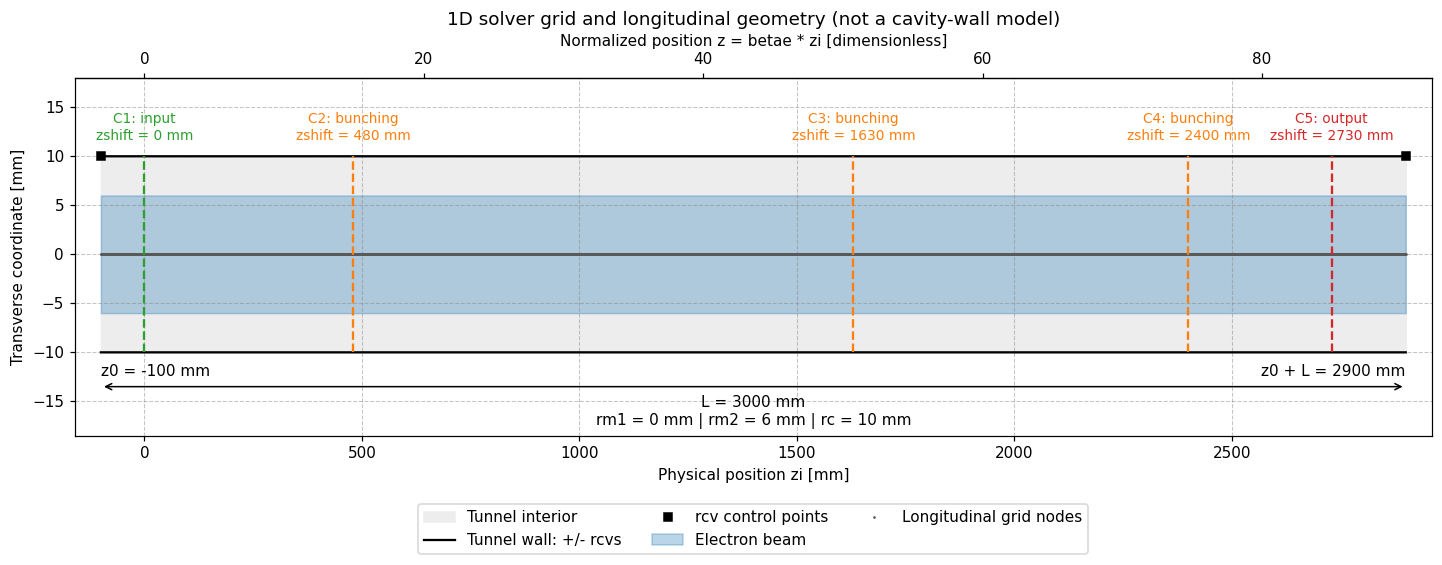

In [19]:
fig, ax = plt.subplots(figsize=(13, 5), layout="constrained")
radius = max(grid.rcvs.max(), rc)

# Draw the tube aperture and its sampled radius profile.
ax.fill_between(
    grid.zi, -grid.rcvs, grid.rcvs,
    color="0.93", label="Tunnel interior",
)
ax.plot(grid.zi, grid.rcvs, color="black", label="Tunnel wall: +/- rcvs")
ax.plot(grid.zi, -grid.rcvs, color="black")
ax.plot(rcv[0], rc * rcv[1], "ks", markersize=5, label="rcv control points")

# Draw the upper and lower beam sections; rm1 > 0 leaves a hollow center.
ax.fill_between(
    grid.zi, rm1, rm2,
    color="tab:blue", alpha=0.3, label="Electron beam",
)
ax.fill_between(grid.zi, -rm2, -rm1, color="tab:blue", alpha=0.3)
ax.plot(
    grid.zi, np.zeros_like(grid.zi), ".",
    color="0.35", markersize=1.5, label="Longitudinal grid nodes",
)

# Mark cavity centers only: no cavity walls or RF fields are drawn here.
labels = {0: "input", 1: "bunching", -1: "output"}
colors = {0: "tab:green", 1: "tab:orange", -1: "tab:red"}
for k in range(Nc):
    ax.vlines(
        zshift[k], -radius, radius,
        color=colors[type[k]], linestyle="--",
    )
    ax.text(
        zshift[k], 1.14 * radius,
        f"C{k + 1}: {labels[type[k]]}\nzshift = {zshift[k]:g} mm",
        ha="center", va="bottom", color=colors[type[k]], fontsize=9,
    )

# Label the physical domain and beam radii.
ax.annotate(
    "",
    xy=(z0, -1.35 * radius),
    xytext=(z0 + L, -1.35 * radius),
    arrowprops={"arrowstyle": "<->", "color": "black"},
)
ax.text(z0 + L / 2, -1.43 * radius, f"L = {L:g} mm", ha="center", va="top")
ax.text(z0, -1.12 * radius, f"z0 = {z0:g} mm", ha="left", va="top")
ax.text(z0 + L, -1.12 * radius, f"z0 + L = {z0 + L:g} mm", ha="right", va="top")
ax.text(
    0.5, 0.03,
    f"rm1 = {rm1:g} mm | rm2 = {rm2:g} mm | rc = {rc:g} mm",
    transform=ax.transAxes, ha="center",
)

# The upper axis shows the same positions in normalized coordinates.
top = ax.secondary_xaxis(
    "top",
    functions=(lambda zi: grid.betae * zi, lambda z: z / grid.betae),
)
top.set_xlabel("Normalized position z = betae * zi [dimensionless]")
top.grid(False)  # Avoid overlaying a second grid with different tick positions.

ax.set(
    xlim=(z0 - 0.02 * L, z0 + 1.02 * L),
    ylim=(-1.85 * radius, 1.8 * radius),
    xlabel="Physical position zi [mm]",
    ylabel="Transverse coordinate [mm]",
    title="1D solver grid and longitudinal geometry (not a cavity-wall model)",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)
plt.show()

## 4. Zoom: nodes, indices, and physical/normalized spacing

`kz` is a zero-based Python grid index. A MATLAB index for the same node would be `kz + 1`.

The first panel displays individual nodes near the middle of the domain. The second checks the spacing over the entire domain. Tiny floating-point differences in `np.diff(zi)` are expected even for a uniform mesh.

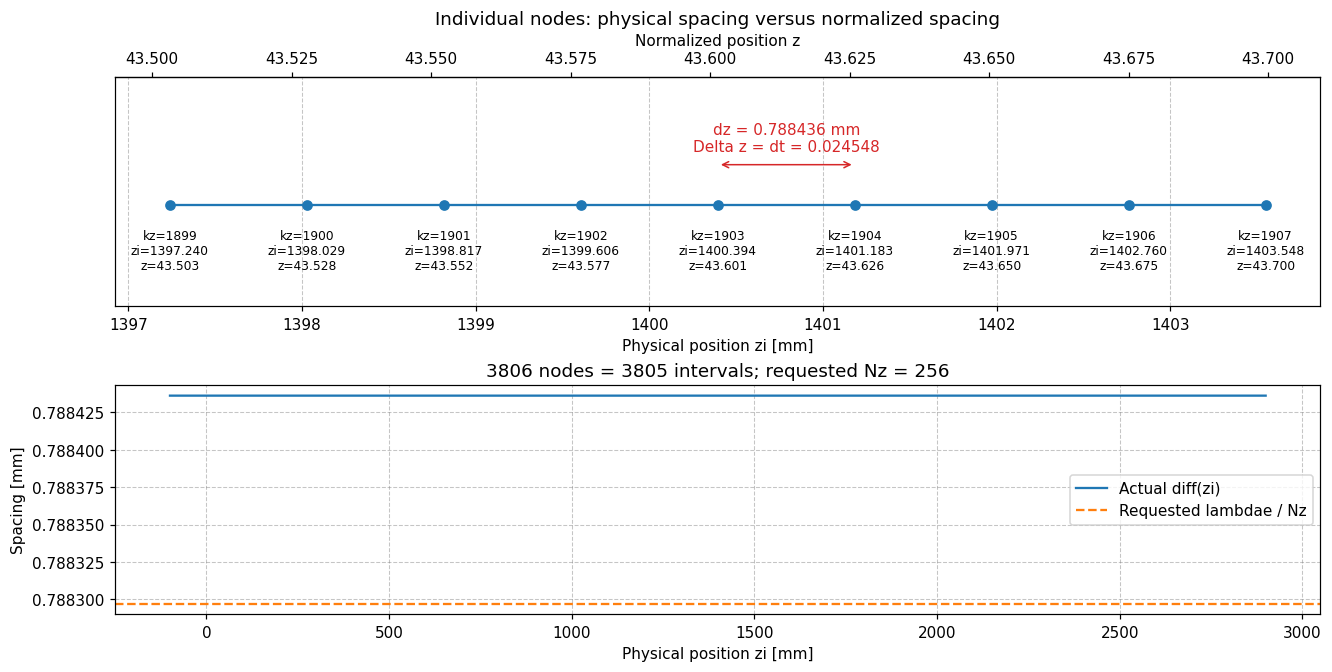

In [20]:
# Select up to nine nodes around the center of the domain.
kz = len(grid.z) // 2
indices = np.arange(max(0, kz - 4), min(len(grid.z), kz + 5))

fig, (ax_nodes, ax_spacing) = plt.subplots(
    2, 1, figsize=(12, 6), layout="constrained",
)

# Upper panel: label each node with its index and both coordinates.
ax_nodes.plot(grid.zi[indices], np.zeros(len(indices)), "o-", color="tab:blue")
for k in indices:
    ax_nodes.text(
        grid.zi[k], -0.18,
        f"kz={k}\nzi={grid.zi[k]:.3f}\nz={grid.z[k]:.3f}",
        ha="center", va="top", fontsize=8,
    )

# The arrow spans exactly one physical grid interval.
ax_nodes.annotate(
    "",
    xy=(grid.zi[kz], 0.30),
    xytext=(grid.zi[kz + 1], 0.30),
    arrowprops={"arrowstyle": "<->", "color": "tab:red"},
)
ax_nodes.text(
    (grid.zi[kz] + grid.zi[kz + 1]) / 2, 0.40,
    f"dz = {grid.dz:.6f} mm\nDelta z = dt = {grid.dt:.6f}",
    ha="center", color="tab:red",
)

top = ax_nodes.secondary_xaxis(
    "top",
    functions=(lambda zi: grid.betae * zi, lambda z: z / grid.betae),
)
top.set_xlabel("Normalized position z")
top.grid(False)

# Vertical placement is schematic, so only the horizontal coordinate has ticks.
ax_nodes.set(
    ylim=(-0.75, 0.95), yticks=[],
    xlabel="Physical position zi [mm]",
    title="Individual nodes: physical spacing versus normalized spacing",
)

# Lower panel: compare the requested spacing with the spacing fitted to L.
ax_spacing.plot(grid.zi[:-1], np.diff(grid.zi), label="Actual diff(zi)")
ax_spacing.axhline(
    dz_requested, color="tab:orange", linestyle="--",
    label="Requested lambdae / Nz",
)
ax_spacing.set(
    xlabel="Physical position zi [mm]",
    ylabel="Spacing [mm]",
    title=f"{len(grid.zi)} nodes = {len(grid.zi) - 1} intervals; requested Nz = {Nz}",
)
ax_spacing.ticklabel_format(axis="y", style="plain", useOffset=False)
ax_spacing.legend()
plt.show()

## 5. Space-charge source windows: dN and Nesz

The grid stores the source indices that the global space-charge calculation will use:

\[
dN=\left\lfloor\frac{\mathrm{factorregion}\,r_c}{\mu_{01}\,dz}\right\rfloor.
\]

For a target node `kz`, `Nesz[kz] = [start, stop]` selects `grid.zi[start:stop]`: **start included, stop excluded**. Away from the boundaries this includes `2*dN + 1` points, including the target. At the entrance and exit, the window is clipped.

This only visualizes the in-domain source window. It does not calculate space charge or add the separate upstream prefill grid `zp`.

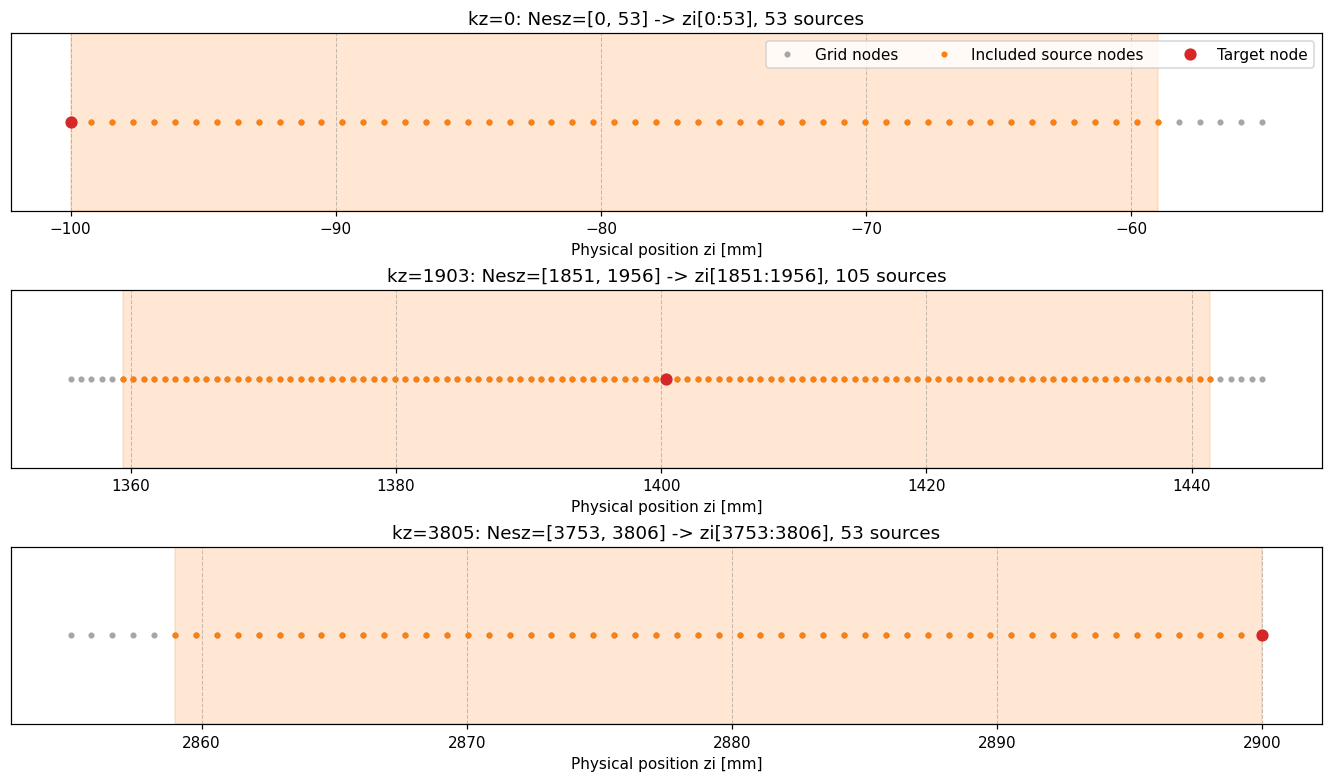

| Variable | Value | Units | Meaning |
|---|---|---|---|
| `Nesz[0]` | [0, 53) | indices | First zi=-100.0000 mm; last included zi=-59.0013 mm |
| `Nesz[1903]` | [1851, 1956) | indices | First zi=1359.3955 mm; last included zi=1441.3929 mm |
| `Nesz[3805]` | [3753, 3806) | indices | First zi=2859.0013 mm; last included zi=2900.0000 mm |


dN = 52; interior half-width = dN*dz = 40.998686 mm
Requested half-width = factorregion*rc/mu01 = 41.582981 mm


In [21]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), layout="constrained")
window_rows = []

# Inspect source windows at the entrance, center, and exit.
target_indices = [0, len(grid.z) // 2, len(grid.z) - 1]
for ax, kz in zip(axes, target_indices):
    start, stop = grid.Nesz[kz]

    # Include a few neighboring nodes to show where the source window ends.
    view_start = max(0, start - 5)
    view_stop = min(len(grid.z), stop + 5)
    ax.plot(
        grid.zi[view_start:view_stop], np.zeros(view_stop - view_start), ".",
        color="0.65", label="Grid nodes",
    )

    # Python excludes stop, so the last included coordinate is zi[stop - 1].
    ax.axvspan(
        grid.zi[start], grid.zi[stop - 1],
        color="tab:orange", alpha=0.18,
    )
    ax.plot(
        grid.zi[start:stop], np.zeros(stop - start), ".",
        color="tab:orange", label="Included source nodes",
    )
    ax.plot(
        grid.zi[kz], 0, "o",
        color="tab:red", markersize=7, label="Target node",
    )
    ax.set(
        ylim=(-0.5, 0.5), yticks=[],
        xlabel="Physical position zi [mm]",
        title=f"kz={kz}: Nesz=[{start}, {stop}] -> zi[{start}:{stop}], {stop - start} sources",
    )

    window_rows.append((
        f"Nesz[{kz}]", f"[{start}, {stop})", "indices",
        f"First zi={grid.zi[start]:.4f} mm; last included zi={grid.zi[stop - 1]:.4f} mm",
    ))

axes[0].legend(loc="upper right", ncol=3)
plt.show()

show_table(window_rows)
print(f"dN = {grid.dN}; interior half-width = dN*dz = {grid.dN * grid.dz:.6f} mm")
print(f"Requested half-width = factorregion*rc/mu01 = {factorregion * rc / mu01:.6f} mm")

## 6. Electron emission/entrance phases: separate from the spatial grid

\[
t_{0,j}=\frac{2\pi j}{N_t},\qquad j=0,\ldots,N_t-1.
\]

Here `tn1 = t0`: the two rows below coincide in phase but have different meanings. `t0` labels emission phases; `tn1` supplies entrance phases. Both are normalized times \(\omega t\), measured as phases in radians, not seconds. Future trajectory arrival phases will be stored separately in `Tnz`.

There is no sample at \(2\pi\): it would duplicate the start of the next RF period. The spacing \(2\pi/N_t\) is distinct from `grid.dt`, which comes from the spatial mesh.

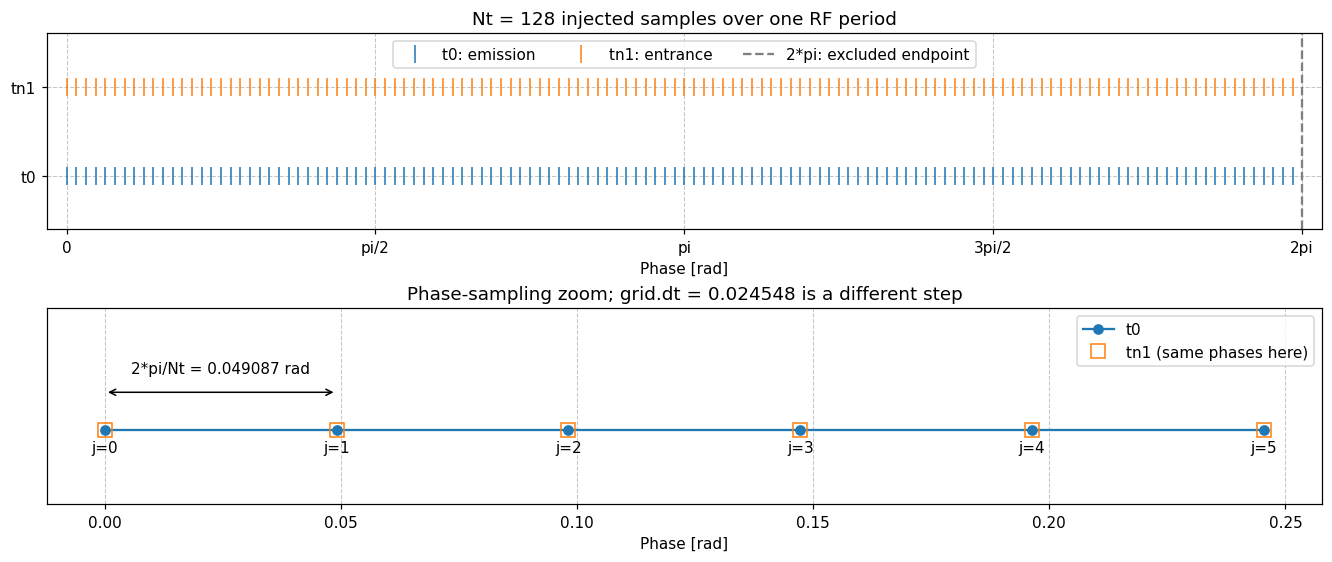

In [22]:
fig, (ax_period, ax_zoom) = plt.subplots(
    2, 1, figsize=(12, 5), layout="constrained",
)

# Upper panel: separate the two rows visually, even when t0 and tn1 coincide.
ax_period.plot(
    t0, np.zeros(Nt), "|",
    markersize=12, label="t0: emission",
)
ax_period.plot(
    tn1, np.ones(Nt), "|",
    markersize=12, label="tn1: entrance",
)
ax_period.axvline(
    2.0 * np.pi, color="0.5", linestyle="--",
    label="2*pi: excluded endpoint",
)
ax_period.set(
    xlim=(-0.1, 2.0 * np.pi + 0.1), ylim=(-0.6, 1.6),
    yticks=[0, 1], yticklabels=["t0", "tn1"],
    xlabel="Phase [rad]",
    title=f"Nt = {Nt} injected samples over one RF period",
)
ax_period.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", "pi/2", "pi", "3pi/2", "2pi"],
)
ax_period.legend(loc="upper center", ncol=3)

# Lower panel: overlay the first samples to see that their phases coincide.
indices = np.arange(min(6, Nt))
ax_zoom.plot(t0[indices], np.zeros(len(indices)), "o-", label="t0")
ax_zoom.plot(
    tn1[indices], np.zeros(len(indices)), "s",
    fillstyle="none", markersize=9, label="tn1 (same phases here)",
)
for j in indices:
    ax_zoom.text(t0[j], -0.12, f"j={j}", ha="center")

# This arrow represents emission-phase spacing, not the spatial grid step dt.
ax_zoom.annotate(
    "",
    xy=(t0[0], 0.2),
    xytext=(t0[1], 0.2),
    arrowprops={"arrowstyle": "<->"},
)
ax_zoom.text(
    (t0[0] + t0[1]) / 2, 0.3,
    f"2*pi/Nt = {2*np.pi/Nt:.6f} rad", ha="center",
)
ax_zoom.set(
    ylim=(-0.4, 0.65), yticks=[],
    xlabel="Phase [rad]",
    title=f"Phase-sampling zoom; grid.dt = {grid.dt:.6f} is a different step",
)
ax_zoom.legend(loc="upper right")
plt.show()

## 7. Basic Python consistency checks

Check endpoints, uniform spacing, coordinate normalization, and source-window indexing. These are internal consistency checks, **not** the future Python–MATLAB comparison.

Use at least two phase samples and enough spatial nodes for the illustrative zoom plots.

In [23]:
expected_intervals = int(np.floor(L / dz_requested))
assert len(grid.zi) == expected_intervals + 1
np.testing.assert_allclose(grid.zi[[0, -1]], [z0, z0 + L])
np.testing.assert_allclose(np.diff(grid.zi), grid.dz, rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(grid.z, grid.betae * grid.zi)
np.testing.assert_allclose(np.diff(grid.z), grid.dt, rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(grid.dt / grid.w, grid.dz * 1e-3 / (reference.s * c))

assert grid.dN == int(np.floor(factorregion * rc / mu01 / grid.dz))
indices = np.arange(len(grid.zi))
np.testing.assert_array_equal(grid.Nesz[:, 0], np.maximum(0, indices - grid.dN))
np.testing.assert_array_equal(grid.Nesz[:, 1], np.minimum(len(grid.zi), indices + grid.dN + 1))

print("Python consistency checks passed. MATLAB comparison has not been run.")
print(f"Nodes: {len(grid.z)} | dz: {grid.dz:.9f} mm | dt: {grid.dt:.9f} | dN: {grid.dN}")

Python consistency checks passed. MATLAB comparison has not been run.
Nodes: 3806 | dz: 0.788436268 mm | dt: 0.024548027 | dN: 52


## 8. Export for the independent MATLAB test

This cell creates or overwrites **only** `inputs.mat` and `python_results.mat` beside this notebook.

- `inputs.mat`: raw beam, cavity, tube and numerical parameters, `factorregion`, and the constants used here. No calculated reference quantities or grid arrays. `Y0` is converted to **one-based indexing** for MATLAB.
- `python_results.mat`: all calculated reference and grid quantities. `Nesz` remains **zero-based with an exclusive stop**, exactly as in Python.
- One-dimensional arrays are saved as row vectors. Matrices keep their dimensions. Real integer inputs are exported as doubles for ordinary MATLAB arithmetic.

The companion MATLAB Live Script loads only `inputs.mat`, calculates independently, and exports `matlab_results.mat`. Rerun both implementations whenever inputs change. No MATLAB calculation or comparison is run by this cell.

In [24]:
inputs = {
    **vars(beam),
    **vars(cavities),
    **vars(tube),
    **vars(numerical),
    "factorregion": factorregion,
    "c": c,
    "etom": etom,
    "mu01": mu01,
}
inputs["Y0"] = beam.Y0 + 1
for name, value in inputs.items():
    if np.asarray(value).dtype.kind in "iub":
        inputs[name] = np.asarray(value, dtype=float)

python_results = {**vars(reference), **vars(grid)}
savemat(test_directory / "inputs.mat", inputs, oned_as="row")
savemat(test_directory / "python_results.mat", python_results, oned_as="row")

print("Saved:", test_directory / "inputs.mat")
print("Saved:", test_directory / "python_results.mat")
print("Next step: run meshgrid_test.mlx (or meshgrid_test.m) in MATLAB.")

Saved: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\1.meshgrid_test\inputs.mat
Saved: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\1.meshgrid_test\python_results.mat
Next step, after review: add the independent MATLAB calculation.
